# 3. Temporal patterns of demand

Daily, weekly, monthly and hourly behaviour of the three cafeterias. Unless stated otherwise,
means are computed over **valid 15-min intervals** only (notebook 2), and daily totals use only
**complete days** (all 96 intervals valid).

`CAF_C1` has very few valid intervals (about 9 % of the period, see notebooks 1 and 2), so its
patterns are shown but should be read with caution.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

import eda_utils as u

u.set_style()
pd.set_option("display.float_format", "{:,.3f}".format)

df = u.build_dataset()
valid = df.dropna(subset=["consumption_L"])
regular = valid[valid["is_weekday"] & ~valid["is_holiday"] & (valid["academic_period"] == "classes")]

def shade_vacations(ax):
    for s, e, label in u.ACADEMIC_PERIODS:
        if label == "vacation":
            ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), color="0.85", lw=0)

## 3.1 Daily demand

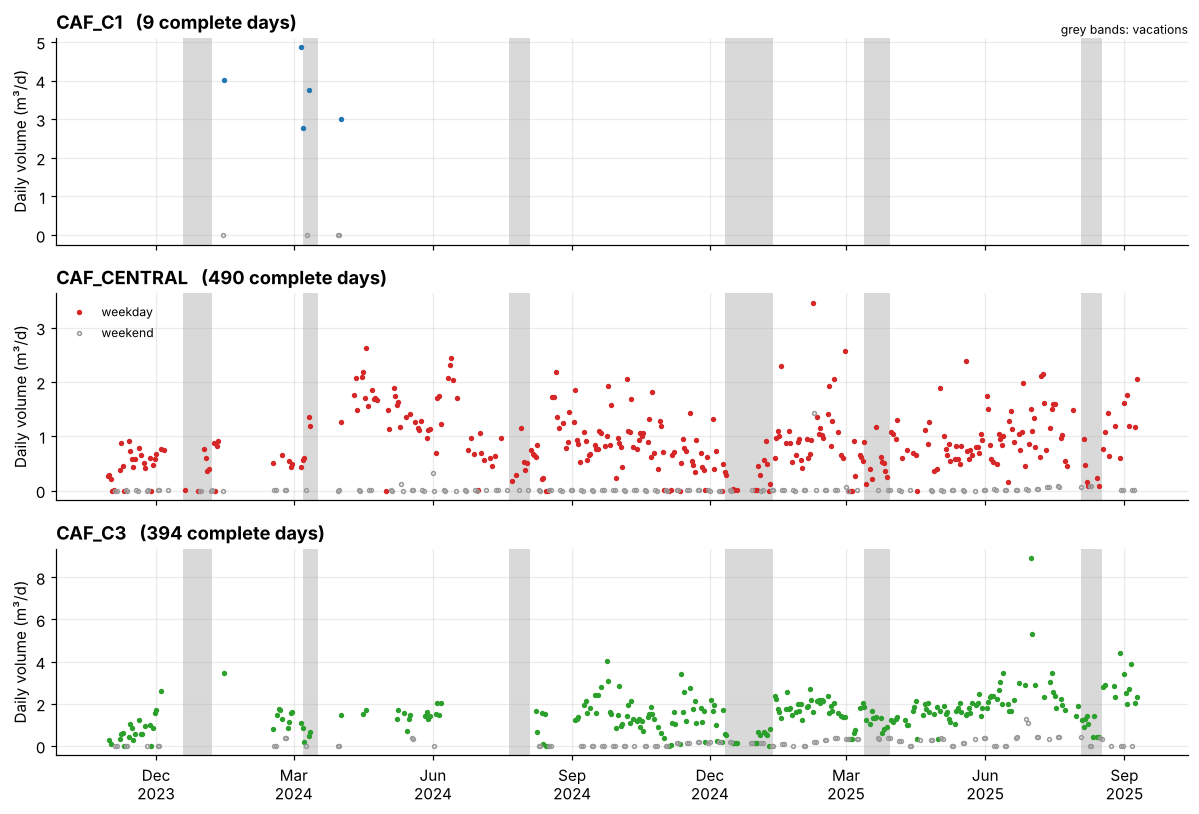

In [2]:
daily = u.daily_totals(df)
fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True)
for ax, caf in zip(axes, u.CAFETERIAS):
    d = daily[daily["cafeteria"] == caf].set_index("date")["volume_L"] / 1000
    weekend = d.index.day_of_week >= 5
    shade_vacations(ax)
    ax.plot(d.index[~weekend], d.values[~weekend], "o", ms=2.5, color=u.COLORS[caf], label="weekday")
    ax.plot(d.index[weekend], d.values[weekend], "o", ms=2.5, mfc="none", color="0.6", label="weekend")
    ax.set_title(f"{caf}   ({len(d)} complete days)", loc="left")
    ax.set_ylabel("Daily volume (m³/d)")
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
axes[1].legend(loc="upper left", fontsize=8)
axes[0].text(1, 1.02, "grey bands: vacations", transform=axes[0].transAxes, ha="right", fontsize=8)
fig.tight_layout()
u.savefig(fig, "03_daily_volume")

In [3]:
daily["day_type"] = np.where(pd.to_datetime(daily["date"]).dt.day_of_week < 5, "weekday", "weekend")
daily.groupby(["cafeteria", "day_type"])["volume_L"].describe()[["count", "mean", "50%", "min", "max"]]

count      mean       50%       min       max
cafeteria   day_type                                                
CAF_C1      weekday    5.000 3,682.600 3,750.000 2,768.000 4,859.000
            weekend    4.000     0.000     0.000     0.000     0.000
CAF_C3      weekday  281.000 1,541.224 1,534.000     0.000 8,910.667
            weekend  113.000   162.801   120.000     0.000 1,268.733
CAF_CENTRAL weekday  344.000   885.894   801.500     0.000 3,460.000
            weekend  146.000    19.071     1.000     0.000 1,425.000

## 3.2 Weekly demand

Mean flow of each week (Monday–Friday, holidays excluded). Weeks run Monday to Sunday and are
labelled by their Monday. Weeks with fewer than 100 valid weekday intervals are left blank.

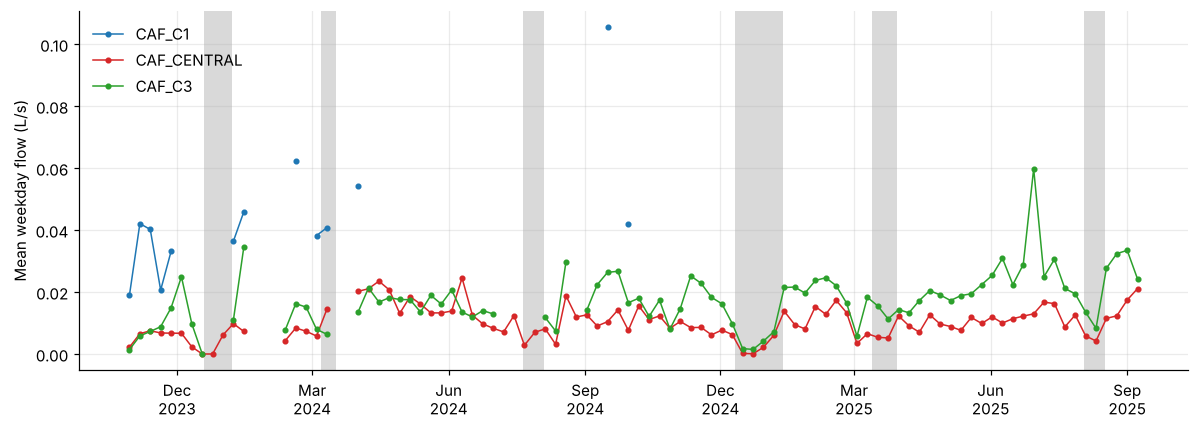

In [4]:
wk = valid[valid["is_weekday"] & ~valid["is_holiday"]]
fig, ax = plt.subplots(figsize=(11, 4))
shade_vacations(ax)
for caf in u.CAFETERIAS:
    g = wk[wk["cafeteria"] == caf]["flow_Ls"].resample("W-SUN")
    weekly = g.mean().where(g.count() >= 100)
    weekly.index = weekly.index - pd.Timedelta(days=6)
    ax.plot(weekly.index, weekly.values, "o-", ms=3, lw=1, color=u.COLORS[caf], label=caf)
ax.set_ylabel("Mean weekday flow (L/s)")
ax.legend(loc="upper left")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.tight_layout()
u.savefig(fig, "03_weekly_flow")

## 3.3 Monthly demand (weekdays, holidays excluded)

Months with fewer than 200 valid weekday intervals are left blank.

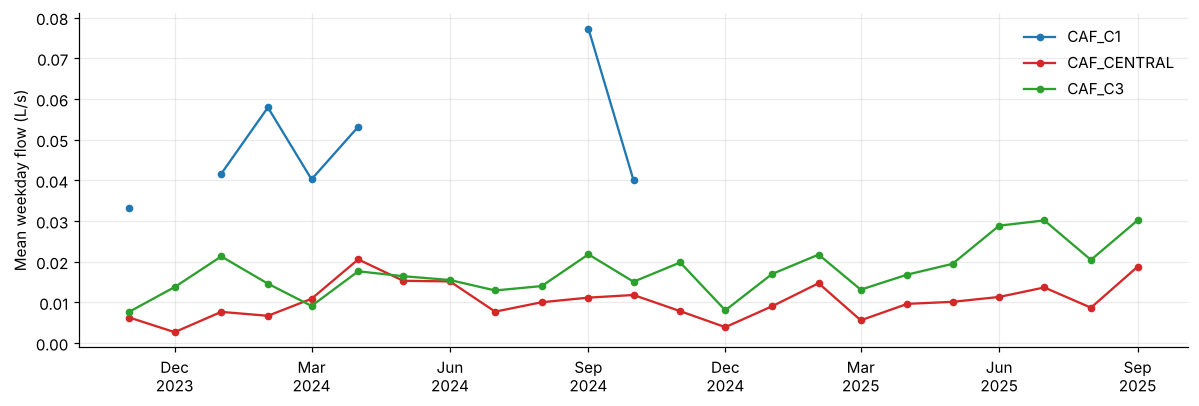

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.8))
for caf in u.CAFETERIAS:
    g = wk[wk["cafeteria"] == caf]["flow_Ls"].resample("MS")
    s = g.mean().where(g.count() >= 200)
    ax.plot(s.index, s.values, "o-", ms=4, color=u.COLORS[caf], label=caf)
ax.set_ylabel("Mean weekday flow (L/s)")
ax.legend()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.tight_layout()
u.savefig(fig, "03_monthly_flow")

## 3.4 Hourly profile on a regular day

Weekdays during classes, holidays excluded. The line is the mean flow of each 15-min slot and
the band is the interquartile range. Dashed lines mark the operating periods.

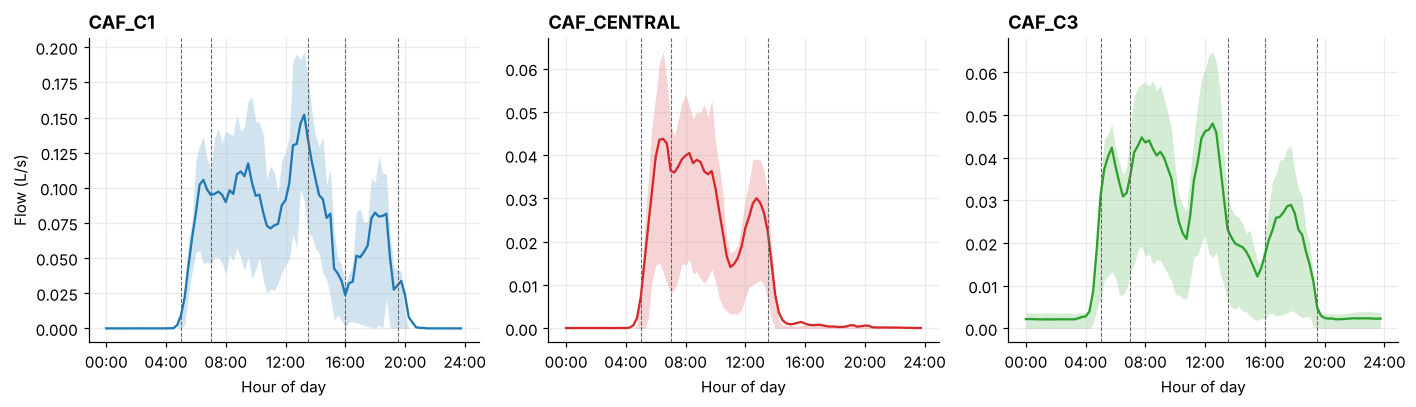

In [6]:
boundaries = [5, 7, 13.5, 16, 19.5]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=False)
for ax, caf in zip(axes, u.CAFETERIAS):
    d = regular[regular["cafeteria"] == caf]
    slot = d.index.hour + d.index.minute / 60
    g = d.groupby(slot)["flow_Ls"]
    ax.fill_between(g.mean().index, g.quantile(0.25), g.quantile(0.75), color=u.COLORS[caf], alpha=0.2, lw=0)
    ax.plot(g.mean().index, g.mean().values, color=u.COLORS[caf], lw=1.5)
    for b in boundaries if caf != "CAF_CENTRAL" else boundaries[:3]:
        ax.axvline(b, color="0.4", ls="--", lw=0.7)
    ax.set_title(caf, loc="left")
    ax.set_xticks(range(0, 25, 4))
    ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 25, 4)])
    ax.set_xlabel("Hour of day")
axes[0].set_ylabel("Flow (L/s)")
fig.tight_layout()
u.savefig(fig, "03_hourly_profile")

In [7]:
peak = (regular.groupby(["cafeteria", regular.index.hour])["flow_Ls"].mean()
               .groupby(level=0).agg(peak_hour="idxmax", peak_flow_Ls="max"))
peak["peak_hour"] = peak["peak_hour"].map(lambda x: f"{x[1]:02d}:00")
peak["mean_flow_Ls"] = regular.groupby("cafeteria")["flow_Ls"].mean()
peak

,peak_hour,peak_flow_Ls,mean_flow_Ls
cafeteria,,,
CAF_C1,13:00,0.138,0.050
CAF_C3,12:00,0.047,0.019
CAF_CENTRAL,06:00,0.042,0.011


## 3.5 Weekdays, weekends and holidays

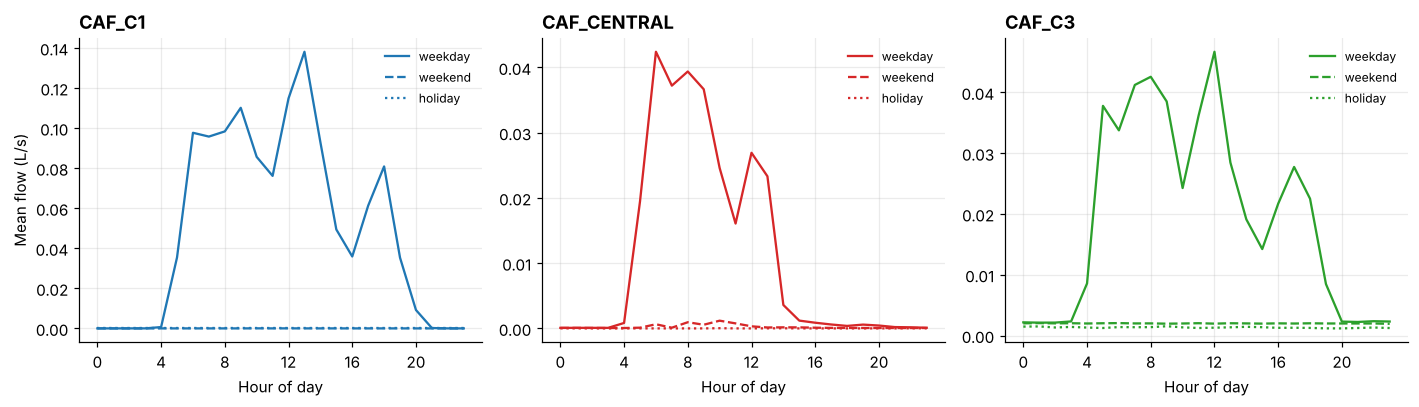

In [8]:
classes = valid[valid["academic_period"] == "classes"]
styles = {"weekday": "-", "weekend": "--", "holiday": ":"}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, caf in zip(axes, u.CAFETERIAS):
    d = classes[classes["cafeteria"] == caf]
    for day_type, ls in styles.items():
        s = d[d["day_type"] == day_type]
        if len(s) > 50:
            p = s.groupby(s.index.hour)["flow_Ls"].mean()
            ax.plot(p.index, p.values, ls, color=u.COLORS[caf], lw=1.5, label=day_type)
    ax.set_title(caf, loc="left")
    ax.set_xticks(range(0, 24, 4))
    ax.set_xlabel("Hour of day")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Mean flow (L/s)")
fig.tight_layout()
u.savefig(fig, "03_day_type_profiles")

## 3.6 Day of the week × hour of day (classes, holidays excluded)

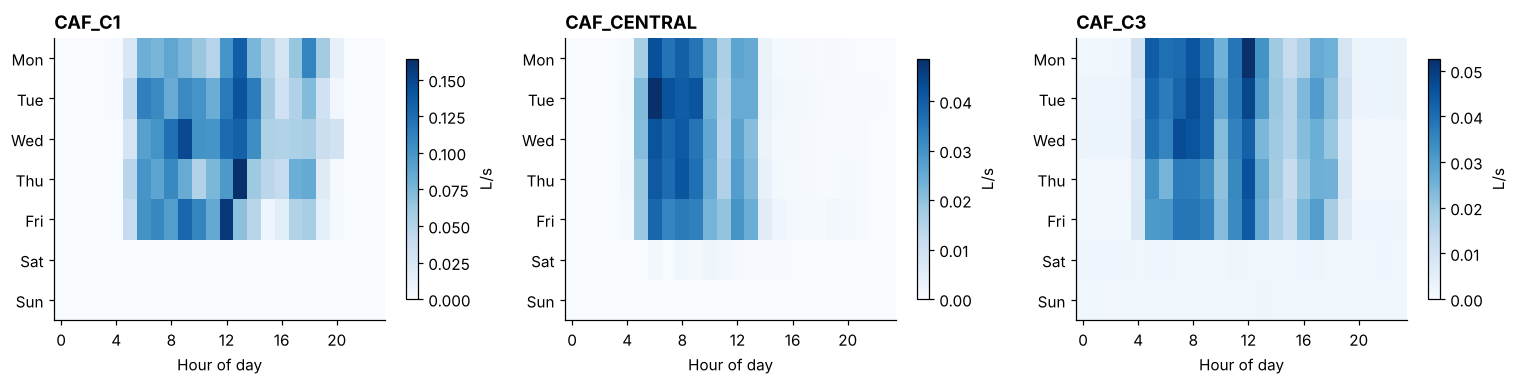

In [9]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
d0 = classes[~classes["is_holiday"]]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, caf in zip(axes, u.CAFETERIAS):
    d = d0[d0["cafeteria"] == caf]
    m = d.pivot_table(index="day_name", columns="hour", values="flow_Ls", aggfunc="mean").reindex(days)
    im = ax.imshow(m.values, aspect="auto", cmap="Blues", vmin=0)
    ax.set_yticks(range(7))
    ax.set_yticklabels([x[:3] for x in days])
    ax.set_xticks(range(0, 24, 4))
    ax.set_xlabel("Hour of day")
    ax.set_title(caf, loc="left")
    ax.grid(False)
    fig.colorbar(im, ax=ax, label="L/s", shrink=0.85)
fig.tight_layout()
u.savefig(fig, "03_weekday_hour_heatmap")

## 3.7 Classes versus vacations (weekdays, holidays excluded)

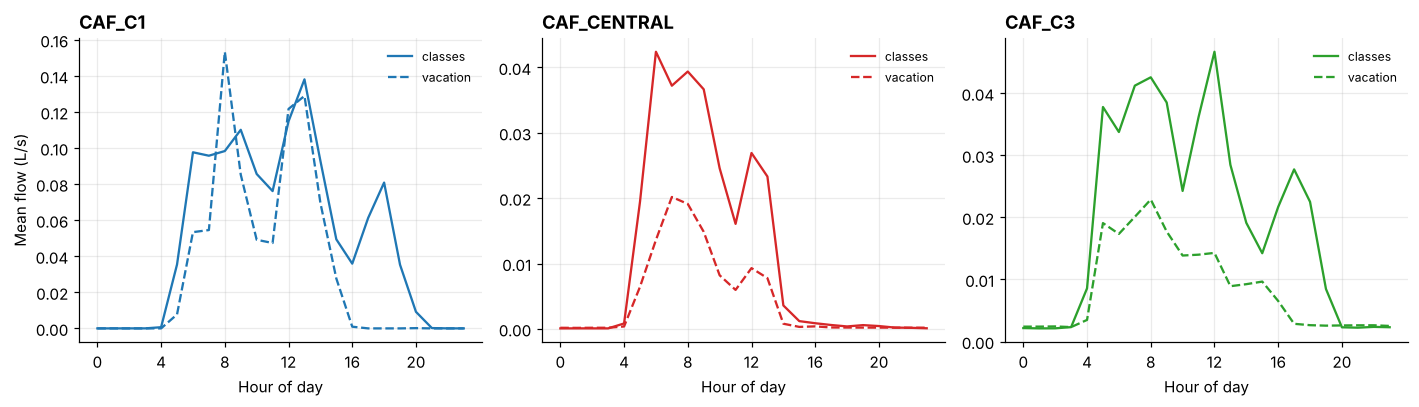

In [10]:
wd = valid[valid["is_weekday"] & ~valid["is_holiday"]]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, caf in zip(axes, u.CAFETERIAS):
    d = wd[wd["cafeteria"] == caf]
    for period, ls in [("classes", "-"), ("vacation", "--")]:
        s = d[d["academic_period"] == period]
        if len(s) > 50:
            p = s.groupby(s.index.hour)["flow_Ls"].mean()
            ax.plot(p.index, p.values, ls, color=u.COLORS[caf], lw=1.5, label=period)
    ax.set_title(caf, loc="left")
    ax.set_xticks(range(0, 24, 4))
    ax.set_xlabel("Hour of day")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Mean flow (L/s)")
fig.tight_layout()
u.savefig(fig, "03_classes_vs_vacation")

In [11]:
(wd.groupby(["cafeteria", "academic_period"])["flow_Ls"].mean().unstack()
   .assign(**{"vacation / classes": lambda t: t["vacation"] / t["classes"]}))

academic_period,classes,vacation,vacation / classes
cafeteria,,,
CAF_C1,0.050,0.034,0.679
CAF_C3,0.019,0.009,0.440
CAF_CENTRAL,0.011,0.005,0.404


## Observations

* **Weekly rhythm.** Demand is concentrated on weekdays. On complete days, `CAF_C3` uses on
  average 1.5 m³/d on weekdays and 0.16 m³/d on weekends; `CAF_CENTRAL` uses 0.89 m³/d and
  0.02 m³/d.
* **Daily profiles.** `CAF_CENTRAL` is a breakfast-oriented cafeteria: its flow peaks at 06:00,
  has a smaller lunch peak around 12:00 and practically stops after 14:00. `CAF_C3` and
  `CAF_C1` serve three meals: a morning plateau (05:00–09:00), a lunch peak (12:00–13:00) and an
  evening peak (17:00–18:00). `CAF_C1` has the highest flows (mean 0.050 L/s on regular
  weekdays, against 0.019 L/s for `CAF_C3` and 0.011 L/s for `CAF_CENTRAL`), but it is
  based on few data.
* **Base flow.** `CAF_C3` keeps a small flow (≈ 0.002 L/s) every hour of the night and on
  weekends; the other two cafeterias drop to zero (see notebook 5).
* **Academic calendar.** During vacations, weekday flow falls to 44 % (`CAF_C3`) and 40 %
  (`CAF_CENTRAL`) of the flow during classes; the shape of the daily profile is kept.
* **Trend.** The weekday flow of `CAF_C3` and `CAF_CENTRAL` rises during 2025; `CAF_C3` roughly
  doubles between March and September 2025.
* **Days to check.** Six weekdays during classes have zero volume in `CAF_CENTRAL`
  (2 Nov 2023, 15–16 Aug 2024, 3 and 5 Mar 2025, 17 Apr 2025). They match days off that the
  national holiday calendar does not include (Día de los Difuntos, the Panama City holiday of
  15 August, Carnival and Holy Thursday). `CAF_C3` has two unusually high days (1–2 July 2025,
  up to 8.9 m³).